In [1]:
from IPython import display
import ultralytics

In [2]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

In [3]:
import cv2
import matplotlib.pyplot as plt

In [4]:
display.clear_output()
ultralytics.checks()

Ultralytics 8.4.177  Python-3.13.5 torch-2.14.1+cpu CPU (13th Gen Intel Core i5-13420H)
Setup complete  (12 CPUs, 15.7 GB RAM, 402.9/475.4 GB disk)


In [5]:
model = ultralytics.YOLO('yolo26n.yaml').load('yolo26n.pt')

Transferred 708/708 items from pretrained weights


In [6]:
img = "dataset/train_polygon/train/images/pixabay_cat_004806.jpg"
result = model.predict(img)


image 1/1 c:\ml_focus\projectyolo\dataset\train_polygon\train\images\pixabay_cat_004806.jpg: 640x640 1 cat, 239.6ms
Speed: 4.4ms preprocess, 239.6ms inference, 2.2ms postprocess per image at shape (1, 3, 640, 640)


1
ultralytics.engine.results.Boxes object with attributes:

cls: tensor([15.])
conf: tensor([0.8430])
data: tensor([[  2.7406,  12.3411, 503.0548, 510.0668,   0.8430,  15.0000]])
id: None
is_track: False
orig_shape: (512, 512)
shape: torch.Size([1, 6])
xywh: tensor([[252.8977, 261.2039, 500.3141, 497.7257]])
xywhn: tensor([[0.4939, 0.5102, 0.9772, 0.9721]])
xyxy: tensor([[  2.7406,  12.3411, 503.0548, 510.0668]])
xyxyn: tensor([[0.0054, 0.0241, 0.9825, 0.9962]])
cat
[3, 12, 503, 510]
0.84


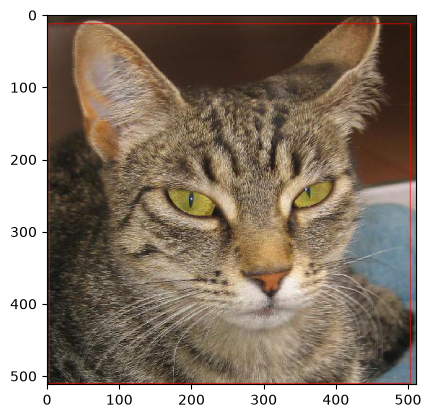

In [7]:
print(len(result[0].boxes))
myimage = cv2.imread(img)
myimage = cv2.cvtColor(myimage, cv2.COLOR_BGR2RGB)
plt.imshow(myimage)

for box in result[0].boxes:
    print(box)
    class_id = result[0].names[box.cls[0].item()]
    print(class_id)
    coor = box.xyxy[0].tolist()
    coors = [round(x)for x in coor ]
    print(coors)
    cf = round(box.conf[0].item(),2)
    print(cf)
    myimage = cv2.rectangle(myimage,(coors[0],coors[1]),(coors[2],coors[3]),(255,0,0))
plt.imshow(myimage)